# 04 — Búsqueda de hiperparámetros: Grid, Random y Optuna
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio/blob/main/notebooks/04_busqueda_hiperparametros.ipynb)

**Integrantes:** David Castro & Alejandro Pardo
**Asignatura:** Machine Learning II — Universidad Externado de Colombia

> Notebook creado después de la retroalimentación de la Segunda entrega (noviembre de 2026).

Hasta ahora los hiperparámetros se buscaron solo con **GridSearchCV**. El objetivo de este notebook **no es cambiarlos,
sino comprobar que la rejilla estaba bien armada**. GridSearch solo prueba los valores que uno le da (por ejemplo,
profundidades 6, 8 y 12); si el mejor valor estuviera entre esos puntos, nunca lo encontraría. Los otros dos buscadores
exploran todo el rango: si alguno encontrara una configuración claramente mejor, la rejilla estaría fallando; si llegan
a lo mismo, los hiperparámetros elegidos no dependen de cómo se armó la rejilla.

Se aplican los tres buscadores vistos en la semana 5 del curso (*Búsqueda de hiperparámetros*) a los dos mejores modelos
del notebook 03, **Random Forest** y **Gradient Boosting**, siguiendo el protocolo de esa sesión:

| Buscador | Cómo propone configuraciones |
|---|---|
| `GridSearchCV` | Todas las combinaciones de una rejilla fija |
| `RandomizedSearchCV` | Configuraciones sorteadas de distribuciones (`randint`, `loguniform`) |
| **Optuna (TPE)** | Aprende de los intentos previos y concentra las nuevas propuestas en las regiones prometedoras |

**Protocolo (declarado antes de ejecutar):**

1. **Mismo presupuesto:** cada buscador evalúa el mismo número de configuraciones que tiene la rejilla
   (24 para Random Forest y 27 para Gradient Boosting).
2. **Mismo espacio:** los rangos de Random y Optuna cubren exactamente los extremos de la rejilla.
3. **Mismos pliegues:** `StratifiedKFold(5)` con semilla 42, la misma partición y el mismo Pipeline de los notebooks 02–03.
4. **Métrica y regla de selección:** mayor *balanced accuracy* media en validación cruzada.
5. **Lectura:** una diferencia entre buscadores menor que la desviación entre pliegues no es evidencia de que un
   buscador sea mejor.
6. **Prueba:** se usa una sola vez, con la configuración elegida de cada modelo.

In [1]:
# === Configuración de rutas (funciona en Colab y en local) ===
import os, sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("ML2-Proyecto-Riesgo-Crediticio").exists():
    !git clone -q https://github.com/AlejandroP212/ML2-Proyecto-Riesgo-Crediticio.git
    os.chdir("ML2-Proyecto-Riesgo-Crediticio")
    !pip install -q optuna==5.0.0

ROOT = Path.cwd()
while not (ROOT / "CHECKSUMS.txt").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA, FIGS, TABLES = ROOT / "data", ROOT / "figuras", ROOT / "resultados"
for d in (DATA, FIGS, TABLES):
    d.mkdir(exist_ok=True)
SEED = 42
print("Raíz del proyecto encontrada:", ROOT.name)

Raíz del proyecto encontrada: ml2-proyecto-riesgo-crediticio


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import optuna
from scipy.stats import randint, loguniform
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV, RandomizedSearchCV,
                                     cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (balanced_accuracy_score, recall_score, precision_score, f1_score,
                             roc_auc_score, confusion_matrix)
from src.modelos_balanceados import GradientBoostingBalanceado

optuna.logging.set_verbosity(optuna.logging.WARNING)
plt.style.use("seaborn-v0_8-whitegrid")
ruta = DATA / "credito_colombia_simulado.csv"
if not ruta.exists():  # si no se ejecutó el notebook 01, se genera aquí
    from src.simulacion_credito import generar_dataset_credito_colombia
    generar_dataset_credito_colombia(6000, SEED).to_csv(ruta, index=False)
df = pd.read_csv(ruta)

X, y = df.drop(columns="incumple"), df["incumple"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED, stratify=y)
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

def make_pipe(model):
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler()),
                     ("classifier", model)])

print(f"Train: {len(X_train)} | Test: {len(X_test)} | optuna {optuna.__version__}")

Train: 4800 | Test: 1200 | optuna 5.0.0


## 1. Espacios de búsqueda
Para cada modelo, la rejilla es la del notebook 03 y las distribuciones de Random y Optuna van del valor mínimo al
máximo de esa rejilla. La tasa de aprendizaje se muestrea en escala logarítmica (`loguniform` / `log=True`), como en
la clase: importa más pasar de 0,02 a 0,04 que de 0,08 a 0,10.

| Modelo | Hiperparámetro | Grid | Random | Optuna |
|---|---|---|---|---|
| Random Forest | `n_estimators` | {100, 200} | `randint(100, 201)` | entero 100–200 |
| | `max_depth` | {6, 8, 12} | `randint(6, 13)` | entero 6–12 |
| | `min_samples_split` | {2, 5} | `randint(2, 6)` | entero 2–5 |
| | `class_weight` | {balanced, balanced_subsample} | igual | igual |
| Gradient Boosting | `n_estimators` | {100, 200, 400} | `randint(100, 401)` | entero 100–400 |
| | `learning_rate` | {0,02; 0,05; 0,1} | `loguniform(0.02, 0.1)` | real 0,02–0,1 (log) |
| | `max_depth` | {1, 2, 3} | `randint(1, 4)` | entero 1–3 |

Ambos modelos usan pesos de clase balanceados (Gradient Boosting mediante `src/modelos_balanceados.py`).

In [3]:
P = "classifier__"
espacios = {
    "Random Forest": {
        "modelo": lambda: RandomForestClassifier(random_state=SEED),
        "grid": {P + "n_estimators": [100, 200], P + "max_depth": [6, 8, 12],
                 P + "min_samples_split": [2, 5], P + "class_weight": ["balanced", "balanced_subsample"]},
        "random": {P + "n_estimators": randint(100, 201), P + "max_depth": randint(6, 13),
                   P + "min_samples_split": randint(2, 6), P + "class_weight": ["balanced", "balanced_subsample"]},
        "optuna": lambda t: {
            P + "n_estimators": t.suggest_int("n_estimators", 100, 200),
            P + "max_depth": t.suggest_int("max_depth", 6, 12),
            P + "min_samples_split": t.suggest_int("min_samples_split", 2, 5),
            P + "class_weight": t.suggest_categorical("class_weight", ["balanced", "balanced_subsample"])},
    },
    "Gradient Boosting": {
        "modelo": lambda: GradientBoostingBalanceado(random_state=SEED),
        "grid": {P + "n_estimators": [100, 200, 400], P + "learning_rate": [0.02, 0.05, 0.1],
                 P + "max_depth": [1, 2, 3]},
        "random": {P + "n_estimators": randint(100, 401), P + "learning_rate": loguniform(0.02, 0.1),
                   P + "max_depth": randint(1, 4)},
        "optuna": lambda t: {
            P + "n_estimators": t.suggest_int("n_estimators", 100, 400),
            P + "learning_rate": t.suggest_float("learning_rate", 0.02, 0.1, log=True),
            P + "max_depth": t.suggest_int("max_depth", 1, 3)},
    },
}
for nombre, e in espacios.items():
    n = int(np.prod([len(v) for v in e["grid"].values()]))
    e["presupuesto"] = n
    print(f"{nombre}: presupuesto = {n} configuraciones por buscador")

Random Forest: presupuesto = 24 configuraciones por buscador
Gradient Boosting: presupuesto = 27 configuraciones por buscador


## 2. Ejecución de los tres buscadores
Para cada configuración se guardan las *balanced accuracy* de los 5 pliegues. Así se reporta la media **y** la
desviación del mejor candidato de cada buscador, y la evolución del mejor resultado a medida que avanza la búsqueda.

In [4]:
def fold_scores(cv_results, i):
    return np.array([cv_results[f"split{k}_test_score"][i] for k in range(5)])

resultados, historia, mejores = [], {}, {}
for nombre, e in espacios.items():
    n = e["presupuesto"]
    historia[nombre] = {}

    # --- GridSearchCV ---
    t0 = time.time()
    gs = GridSearchCV(make_pipe(e["modelo"]()), e["grid"], cv=cv5, scoring="balanced_accuracy", n_jobs=-1).fit(X_train, y_train)
    s = fold_scores(gs.cv_results_, gs.best_index_)
    resultados.append({"Modelo": nombre, "Buscador": "Grid", "Configuraciones": n, "CV media": s.mean(),
                       "CV desv": s.std(), "Tiempo (s)": time.time() - t0})
    historia[nombre]["Grid"] = np.full(n, gs.best_score_)       # la rejilla no tiene orden: solo su mejor valor
    mejores[(nombre, "Grid")] = gs.best_params_

    # --- RandomizedSearchCV ---
    t0 = time.time()
    rs = RandomizedSearchCV(make_pipe(e["modelo"]()), e["random"], n_iter=n, cv=cv5, scoring="balanced_accuracy",
                            random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    s = fold_scores(rs.cv_results_, rs.best_index_)
    resultados.append({"Modelo": nombre, "Buscador": "Random", "Configuraciones": n, "CV media": s.mean(),
                       "CV desv": s.std(), "Tiempo (s)": time.time() - t0})
    historia[nombre]["Random"] = np.maximum.accumulate(rs.cv_results_["mean_test_score"])
    mejores[(nombre, "Random")] = rs.best_params_

    # --- Optuna (TPE) ---
    def objetivo(trial, e=e):
        pipe = make_pipe(e["modelo"]()).set_params(**e["optuna"](trial))
        s = cross_val_score(pipe, X_train, y_train, cv=cv5, scoring="balanced_accuracy", n_jobs=-1)
        trial.set_user_attr("folds", s.tolist())
        return s.mean()

    t0 = time.time()
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objetivo, n_trials=n)
    s = np.array(study.best_trial.user_attrs["folds"])
    resultados.append({"Modelo": nombre, "Buscador": "Optuna (TPE)", "Configuraciones": n, "CV media": s.mean(),
                       "CV desv": s.std(), "Tiempo (s)": time.time() - t0})
    historia[nombre]["Optuna (TPE)"] = np.maximum.accumulate([t.value for t in study.trials])
    mejores[(nombre, "Optuna (TPE)")] = {P + k: v for k, v in study.best_params.items()}

tabla4 = pd.DataFrame(resultados)
tabla4["Diferencia con el mejor"] = tabla4["CV media"] - tabla4.groupby("Modelo")["CV media"].transform("max")
tabla4.drop(columns="Tiempo (s)").round(4).to_csv(TABLES / "tabla4_buscadores_hiperparametros.csv", index=False)  # el tiempo depende del equipo
tabla4.round(4)

,Modelo,Buscador,Configuraciones,CV media,CV desv,Tiempo (s),Diferencia con el mejor
0,Random Forest,Grid,24,0.8842,0.0257,32.5299,0.0000
1,Random Forest,Random,24,0.8802,0.0282,32.6340,-0.0040
2,Random Forest,Optuna (TPE),24,0.8827,0.0255,33.6869,-0.0015
3,Gradient Boosting,Grid,27,0.8939,0.0082,58.3676,-0.0022
4,Gradient Boosting,Random,27,0.8921,0.0078,61.2313,-0.0040
5,Gradient Boosting,Optuna (TPE),27,0.8960,0.0099,68.3570,0.0000


### 2.1 Mejor configuración encontrada por cada buscador

In [5]:
for nombre in espacios:
    print(nombre)
    display(pd.DataFrame([{"Buscador": b, **{k.replace(P, ""): (round(v, 4) if isinstance(v, float) else v)
                                           for k, v in p.items()}}
                          for (m, b), p in mejores.items() if m == nombre]).set_index("Buscador"))

Random Forest


,class_weight,max_depth,min_samples_split,n_estimators
Buscador,,,,
Grid,balanced,6,5,100
Random,balanced,7,5,188
Optuna (TPE),balanced,6,3,138


Gradient Boosting


,learning_rate,max_depth,n_estimators
Buscador,,,
Grid,0.0500,1,400
Random,0.0365,1,370
Optuna (TPE),0.0699,1,343


## 3. ¿Cómo avanza cada búsqueda?
Mejor *balanced accuracy* acumulada en validación cruzada según el número de configuraciones evaluadas. La rejilla no
tiene un orden de exploración, así que se muestra solo su mejor valor como referencia.

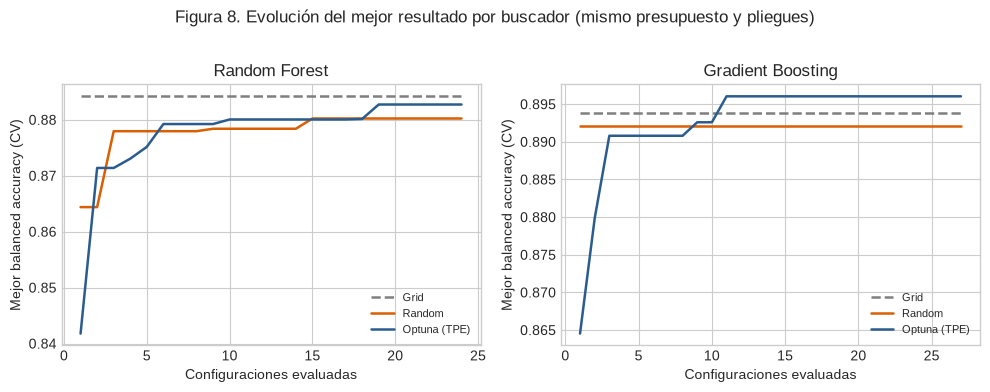

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
colores = {"Grid": "#7f7f7f", "Random": "#d95f02", "Optuna (TPE)": "#2b5c8f"}
for ax, (nombre, h) in zip(axes, historia.items()):
    x = np.arange(1, espacios[nombre]["presupuesto"] + 1)
    for b, v in h.items():
        ax.plot(x, v, label=b, color=colores[b], lw=1.8, ls="--" if b == "Grid" else "-")
    ax.set(title=nombre, xlabel="Configuraciones evaluadas", ylabel="Mejor balanced accuracy (CV)")
    ax.legend(fontsize=8, loc="lower right")
fig.suptitle("Figura 8. Evolución del mejor resultado por buscador (mismo presupuesto y pliegues)", y=1.02)
plt.tight_layout(); plt.savefig(FIGS / "fig8_buscadores_hiperparametros.png", dpi=300, bbox_inches="tight"); plt.show()

## 4. Selección y evaluación en prueba
Por la regla declarada, para cada modelo se toma la configuración con mayor CV media entre los tres buscadores, se
reajusta con todo el entrenamiento y se evalúa **una sola vez** en la prueba.

In [7]:
filas = []
for nombre, e in espacios.items():
    t = tabla4[tabla4.Modelo == nombre]
    gan = t.loc[t["CV media"].idxmax(), "Buscador"]
    modelo = make_pipe(e["modelo"]()).set_params(**mejores[(nombre, gan)]).fit(X_train, y_train)
    pred, score = modelo.predict(X_test), modelo.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas.append({"Modelo": nombre, "Buscador elegido": gan,
                  "Test Bal. Acc": balanced_accuracy_score(y_test, pred), "Test Recall": recall_score(y_test, pred),
                  "Test Precision": precision_score(y_test, pred), "Test F1": f1_score(y_test, pred),
                  "Test ROC-AUC": roc_auc_score(y_test, score),
                  "Morosos detectados": f"{tp} de {tp + fn}", "Falsas alarmas": fp})
pd.DataFrame(filas).round(4)

,Modelo,Buscador elegido,Test Bal. Acc,Test Recall,Test Precision,Test F1,Test ROC-AUC,Morosos detectados,Falsas alarmas
0,Random Forest,Grid,0.8659,0.8529,0.3955,0.5404,0.9434,87 de 102,133
1,Gradient Boosting,Optuna (TPE),0.8851,0.8922,0.4044,0.5566,0.9544,91 de 102,134


## 5. Lectura

**1. Con este presupuesto, ningún buscador es mejor que otro.** Dentro de cada modelo, las diferencias entre Grid,
Random y Optuna son de 0,004 o menos, mientras que la desviación entre pliegues es de 0,008 a 0,028. Siguiendo la regla
de la clase, una diferencia menor que la variación entre pliegues no es evidencia de que un buscador sea superior.

**2. Los tres llegan a la misma región, y eso da confianza en el ajuste.** Para Random Forest, los tres eligen
`class_weight='balanced'` y una profundidad de 6 a 7. Para Gradient Boosting, los tres eligen árboles de un solo nivel
(`max_depth=1`), entre 343 y 400 árboles y una tasa de aprendizaje de 0,04 a 0,07. Que tres métodos distintos coincidan
indica que los hiperparámetros del proyecto no dependen de cómo se armó la rejilla.

**3. Por qué Grid es suficiente aquí.** Los espacios son pequeños (3 o 4 hiperparámetros, 24 o 27 configuraciones), y
ese es justamente el caso en que la clase recomienda Grid por reproducibilidad y facilidad de explicación. Optuna gana
valor cuando hay muchas dimensiones o un presupuesto mayor; queda listo para la entrega final si se agregan modelos con
más hiperparámetros, como XGBoost o LightGBM.

**4. Estas cifras de CV son optimistas.** Como advierte la clase, probar varias configuraciones sobre los mismos
pliegues favorece a la que tuvo suerte en ellos. Aquí Gradient Boosting aparece por encima de Random Forest (0,896 frente
a 0,884), pero la comparación honesta entre modelos es la CV anidada del notebook 03 (Random Forest 0,891 ± 0,011;
Gradient Boosting 0,888 ± 0,007), donde no se distinguen.

**5. En la prueba, los resultados coinciden con el notebook 03.** Random Forest: 0,866 y 87 de 102 morosos detectados.
Gradient Boosting con la configuración de Optuna: 0,885 y 91 de 102.

**6. Siguiente búsqueda (reto de la clase).** En Gradient Boosting el número de árboles quedó cerca del máximo (343–400)
y la profundidad en el mínimo (1). Una segunda búsqueda debería fijar `max_depth=1` y ampliar el rango de
`n_estimators`, manteniendo amplia la tasa de aprendizaje.